# BER results extraction by dwelling type and BER band

This notebook turns the SEAI BER public search extract (`BERPublicsearch.txt`) into national summary tables.

| Request | Section |
|---|---|
| 1. Learn the caveats of the data | **2. Data caveats** (each caveat is shown with evidence from the file) and **3. Cleaning** |
| 2. Split the data into *flat*, *semi-detached* and *detached* | **4. Dwelling type split** |
| 3. Extract results by BER band and dwelling type for consumption, U-values, energy indicators and area | **5. Derived metrics**, **7. Results** and **8. Export** |
| 4. Group the data so results are not split by county | **6. Removing the county split** |

**Outputs** (written to `outputs/`):
- `ber_results_by_type_and_band.xlsx`: one sheet per theme (area, U-values, consumption, energy indicators) at two levels of detail (15 legacy bands A1 to G, and 7 letters A to G), plus the cleaning log, the dwelling type map and metric definitions.
- `ber_summary_by_band.csv` and `ber_summary_by_letter.csv`: the same results as flat CSV files.

Running the whole notebook takes a few minutes (about 2 on a 4-core machine) and needs about 4 GB of RAM. The data file is stored with Git LFS (`git lfs pull`).

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

DATA_PATH = Path('BERPublicsearch.txt')
OUTPUT_DIR = Path('outputs')

# Analysis switches. Section 2 explains why each default was chosen.
EXCLUDE_PROVISIONAL = True     # design-stage ratings: the same dwelling gets a Final rating later
DROP_EXACT_DUPLICATES = False  # identical certificates are mostly identical units in new developments
INFER_GENERIC_HOUSE = True     # assign legacy 'House' records to detached / semi-detached from their geometry
MIN_CELL_N = 30                # result cells with fewer certificates are flagged as low_n

## 1. Load the data

The file is tab separated, Latin-1 encoded, with one certificate per line and 211 columns. Free-text columns (wall descriptions, renewable energy comments) contain stray double quotes, so the file must be read with quoting switched off (`csv.QUOTE_NONE`). The earlier notebooks use pandas' default quoting with `on_bad_lines='skip'`, and that silently merges or drops about 1,600 certificates.

Before parsing, one pass over the raw lines counts them and hashes each one. The count checks that every line became a row. The hashes find exact duplicate certificates across all 211 columns, even though only a subset of columns is loaded.

In [2]:
line_hashes = []
n_lines_with_quote = 0
with DATA_PATH.open('rb') as f:
    n_header_columns = f.readline().count(b'\t') + 1
    for line in f:
        line = line.rstrip(b'\r\n')
        line_hashes.append(hash(line))
        n_lines_with_quote += b'"' in line
line_hashes = pd.Series(line_hashes)

print(f'Data lines: {len(line_hashes):,} | header columns: {n_header_columns}')
print(f'Lines containing a double quote character: {n_lines_with_quote:,}')

Data lines: 1,416,995 | header columns: 211
Lines containing a double quote character: 765


In [3]:
DELIVERED_COLS = ['DeliveredLightingEnergy', 'DeliveredEnergyPumpsFans', 'DeliveredEnergyMainWater',
                  'DeliveredEnergyMainSpace', 'DeliveredEnergySecondarySpace', 'DeliveredEnergySupplementaryWater']
PRIMARY_COLS = ['PrimaryEnergyLighting', 'PrimaryEnergyPumpsFans', 'PrimaryEnergyMainWater',
                'PrimaryEnergyMainSpace', 'PrimaryEnergySecondarySpace', 'PrimaryEnergySupplementaryWater']
FLOOR_COLS = ['GroundFloorArea', 'GroundFloorHeight', 'FirstFloorArea', 'FirstFloorHeight',
              'SecondFloorArea', 'SecondFloorHeight', 'ThirdFloorArea', 'ThirdFloorHeight', 'RoomInRoofArea']
RENEWABLE_COLS = [f'{n}{suffix}' for n in ('First', 'Second', 'Third')
                  for suffix in ('EnergyType_Description', 'EnerProdDelivered')]
USECOLS = (['CountyName', 'DwellingTypeDescr', 'Year_of_Construction', 'TypeofRating', 'EnergyRating',
            'BerRating', 'GroundFloorArea(sq m)', 'UValueWall', 'UValueRoof', 'UValueFloor', 'UValueWindow',
            'UvalueDoor', 'WallArea', 'RoofArea', 'FloorArea', 'WindowArea', 'DoorArea', 'NoStoreys',
            'CO2Rating', 'MainSpaceHeatingFuel', 'HSMainSystemEfficiency', 'ThermalBridgingFactor',
            'TotalDeliveredEnergy', 'DateOfAssessment', 'FirstBoilerFuelType', 'EPC', 'CPC', 'RER']
           + DELIVERED_COLS + PRIMARY_COLS + FLOOR_COLS + RENEWABLE_COLS)

raw = pd.read_csv(DATA_PATH, sep='\t', encoding='latin-1', quoting=csv.QUOTE_NONE,
                  usecols=USECOLS, low_memory=False)
assert len(raw) == len(line_hashes), 'every line must become exactly one row'

raw['is_exact_duplicate'] = line_hashes.duplicated(keep=False).to_numpy()
raw['is_redundant_duplicate'] = line_hashes.duplicated(keep='first').to_numpy()
del line_hashes

print(f'Loaded {len(raw):,} certificates x {len(USECOLS)} of {n_header_columns} columns')

Loaded 1,416,995 certificates x 55 of 211 columns


## 2. Data caveats

Each caveat below is demonstrated in the code cell that follows it. In summary:

| # | Caveat | How it is handled |
|---|---|---|
| 2.1 | Text fields are fixed-width: padded with spaces and cut at 30 characters (fuel names such as `Wood Pellets (bulk supply for`) | Whitespace stripped; truncated labels left as they are |
| 2.2 | `GroundFloorArea(sq m)` is the **total** floor area of the dwelling, not the ground floor | Used as total floor area (TFA) for every per-m² figure |
| 2.3 | `BerRating` is calculated **primary** energy (kWh/m²/yr) net of on-site renewable credits, so it can be negative. `TotalDeliveredEnergy` is filled for only about a third of rows. Group (district) heating dwellings have no per-dwelling delivered energy | BER used as published; delivered energy rebuilt from its end-use components; group heating flagged |
| 2.4 | Two BER scales coexist. Most certificates use the 15-band legacy scale (A1 to G); certificates from mid-2026 use a new 8-label scale (A0, A to G) with different thresholds, so `F` and `G` mean different things on the two scales | Band re-derived from the numeric `BerRating` on the legacy thresholds for every certificate |
| 2.5 | There is no dwelling ID. *Provisional* ratings precede a *Final* rating for the same new dwelling, dwellings are re-rated over time, and some certificates are byte-identical | Provisional excluded; exact duplicates flagged (switch at the top) |
| 2.6 | A U-value of 0 means the element is absent (for example, a mid-floor flat has no exposed roof or floor), not that it is perfectly insulated | U-values averaged by element area, over dwellings that have the element |
| 2.7 | Legacy dwelling codes `House` and `Apartment` (2007 to 2012) do not say whether the dwelling is attached; `Maisonette` and `Basement Dwelling` are rare | Mapped in section 4; `House` inferred from geometry |
| 2.8 | Implausible values: assessment dates in 2109, 2408 and 2703; construction year 2104; floor areas from 5 m² to 3,500 m²; BER up to 32,000 kWh/m²/yr | Removed by explicit rules in section 3 |
| 2.9 | `CountyName` mixes 26 counties, 4 cities and 24 Dublin postal districts (55 values) | Collapsed to county and region, then pooled nationally (section 6) |
| 2.10 | BER is an *asset rating* under standard occupancy and climate, not metered consumption; the method (DEAP) and its primary-energy factors changed over time; certificates are not a random sample of the housing stock | Interpretation notes only; see 2.10 |

### 2.1 Fixed-width text fields

In [4]:
text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
for col in ['TypeofRating', 'MainSpaceHeatingFuel']:
    print(f'{col}: {[repr(v) for v in raw[col].dropna().unique()[:3]]}')

raw[text_cols] = raw[text_cols].apply(lambda s: s.str.strip())

fuels = pd.Series(raw['MainSpaceHeatingFuel'].dropna().unique())
print('\nFuel labels cut at 30 characters:', sorted(fuels[fuels.str.len() == 30]))

TypeofRating: ["'Final          '", "'Existing       '", "'Provisional    '"]


MainSpaceHeatingFuel: ["'Electricity                   '", "'Mains Gas                     '", "'Heating Oil                   '"]



Fuel labels cut at 30 characters: ['Biodiesel from renewable sourc', 'Bioethanol from renewable sour', 'Electricity - Off-peak Night-R', 'Electricity - On-peak Night-Ra', 'Electricity - Standard Domesti', 'Wood Pellets (in bags for seco']


In [5]:
raw['assessment_date'] = pd.to_datetime(raw['DateOfAssessment'], format='%b %d %Y %I:%M%p', errors='coerce')
raw['tfa_m2'] = raw['GroundFloorArea(sq m)']
print(f"Unparseable assessment dates: {raw['assessment_date'].isna().sum():,}")

Unparseable assessment dates: 0


### 2.2 `GroundFloorArea(sq m)` is the total floor area

The sum of the individual floor areas (ground, first, second, third, room in roof) equals `GroundFloorArea(sq m)` for every certificate. The actual ground floor is a separate column (`GroundFloorArea`), which for a two-storey house is about half the total.

In [6]:
floor_sum = raw[['GroundFloorArea', 'FirstFloorArea', 'SecondFloorArea', 'ThirdFloorArea', 'RoomInRoofArea']].sum(axis=1)
ratio = floor_sum / raw['tfa_m2']
print(f"sum of floor areas / 'GroundFloorArea(sq m)': within 1% for {(ratio.sub(1).abs() < 0.01).mean():.2%} of rows")
print(f"'GroundFloorArea' / 'GroundFloorArea(sq m)': median {(raw['GroundFloorArea'] / raw['tfa_m2']).median():.2f}")

sum of floor areas / 'GroundFloorArea(sq m)': within 1% for 100.00% of rows
'GroundFloorArea' / 'GroundFloorArea(sq m)': median 0.57


### 2.3 Energy fields: BER, delivered energy and group heating

- **BER** (`BerRating`, kWh/m²/yr) is primary energy. It equals the sum of the six `PrimaryEnergy*` end uses divided by TFA, except where the dwelling has on-site renewable electricity (PV): the PV credit is subtracted from the BER but not from the end-use columns. This is why A1 dwellings can have negative BERs.
- **Delivered energy** (what is bought: the closest thing to *consumption* in the file) is split into six end uses. `TotalDeliveredEnergy` is their sum but is only filled for some years, so the total is rebuilt from the components. An empty `DeliveredEnergySecondarySpace` or `DeliveredEnergySupplementaryWater` means *no secondary system*: the matching primary-energy column is 0 for every such row.
- **Group heating**: certificates with a group (communal or district) heating scheme fill the `FirstBoilerFuelType` and heat-plant columns instead of `MainSpaceHeatingFuel`. For these, per-dwelling delivered energy is mostly missing, so consumption figures for flats describe individually heated flats.

In [7]:
def renewable_electricity_kwh(d):
    """On-site renewable electricity (PV) declared on the certificate, kWh/yr."""
    parts = [d[f'{n}EnerProdDelivered'].where(d[f'{n}EnergyType_Description'] == 'Renewable Electrical', 0)
             for n in ('First', 'Second', 'Third')]
    total = sum(p.fillna(0) for p in parts)
    return total.where(d['FirstEnergyType_Description'].notna())

raw['renewable_elec_kwh'] = renewable_electricity_kwh(raw)
raw['is_group_heating'] = raw['FirstBoilerFuelType'].notna()

pe_per_m2 = raw[PRIMARY_COLS].sum(axis=1, min_count=len(PRIMARY_COLS)) / raw['tfa_m2']
matches_ber = (pe_per_m2 / raw['BerRating']).sub(1).abs() < 0.02
has_pv = raw['renewable_elec_kwh'] > 0
print('Share of certificates where sum(PrimaryEnergy*) / TFA matches BerRating within 2%:')
print(matches_ber.groupby(has_pv.map({True: 'with PV', False: 'without PV'})).mean().map('{:.1%}'.format).to_string())
print(f"\nNegative BerRating: {(raw['BerRating'] < 0).sum():,} certificates "
      f"({(raw.loc[raw['BerRating'] < 0, 'renewable_elec_kwh'] > 0).mean():.0%} of them have PV)")

Share of certificates where sum(PrimaryEnergy*) / TFA matches BerRating within 2%:
renewable_elec_kwh
with PV        0.1%
without PV    97.8%

Negative BerRating: 4,887 certificates (95% of them have PV)


In [8]:
components = raw[DELIVERED_COLS].fillna(0).sum(axis=1)
has_total = raw['TotalDeliveredEnergy'].notna()
print(f'TotalDeliveredEnergy filled: {has_total.mean():.1%} of rows; '
      f"equals the sum of components (within 1%): {((raw.loc[has_total, 'TotalDeliveredEnergy'] / components[has_total]).sub(1).abs() < 0.01).mean():.1%}")

no_secondary = raw['DeliveredEnergySecondarySpace'].isna() & raw['DeliveredEnergyMainSpace'].notna()
print(f'Secondary space heating empty: {no_secondary.sum():,} rows; '
      f"max PrimaryEnergySecondarySpace on those rows = {raw.loc[no_secondary, 'PrimaryEnergySecondarySpace'].max()}")

missing_main = raw['DeliveredEnergyMainSpace'].isna()
print(f'\nMain space heating delivered energy missing: {missing_main.sum():,} rows')
print(pd.crosstab(raw['is_group_heating'], missing_main, margins=True)
      .rename_axis(index='group heating', columns='delivered energy missing'))
print('\nMissing delivered energy outside group heating, by assessment year (concentrated in 2019):')
print(raw.loc[missing_main & ~raw['is_group_heating'], 'assessment_date'].dt.year.value_counts().sort_index().tail(10).to_string())

TotalDeliveredEnergy filled: 34.2% of rows; equals the sum of components (within 1%): 100.0%
Secondary space heating empty: 356,848 rows; max PrimaryEnergySecondarySpace on those rows = 0.0

Main space heating delivered energy missing: 39,419 rows
delivered energy missing    False   True      All
group heating                                    
False                     1375713  16376  1392089
True                         1863  23043    24906
All                       1377576  39419  1416995

Missing delivered energy outside group heating, by assessment year (concentrated in 2019):
assessment_date
2014        1
2017        1
2018       54
2019    16310
2020        7
2023        3


### 2.4 Two BER scales in one column

Labels `A0`, `A`, `B`, `C`, `D` and `E` (no digit) belong to the new scale, which took over during May and June 2026. On the new scale, B covers 75 to 150, C 150 to 225, D 225 to 275, E 275 to 325 and F 325 to 375 kWh/m²/yr; on the legacy scale F is 380 to 450. The same letter therefore means different things depending on the certificate date, and the band has to be re-derived from `BerRating`.

In [9]:
LEGACY_BANDS = ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3', 'D1', 'D2', 'E1', 'E2', 'F', 'G']
LEGACY_UPPER = [25, 50, 75, 100, 125, 150, 175, 200, 225, 260, 300, 340, 380, 450, np.inf]  # kWh/m2/yr, upper bound inclusive
LETTERS = list('ABCDEFG')
NEW_SCALE_ONLY = ['A0', 'A', 'B', 'C', 'D', 'E']

label_summary = (raw.groupby('EnergyRating')
                 .agg(certificates=('BerRating', 'size'), ber_min=('BerRating', 'min'), ber_max=('BerRating', 'max'),
                      first_assessed=('assessment_date', 'min'))
                 .reindex(['A0', 'A'] + LEGACY_BANDS[:3] + ['B'] + LEGACY_BANDS[3:6] + ['C'] + LEGACY_BANDS[6:9]
                          + ['D'] + LEGACY_BANDS[9:11] + ['E'] + LEGACY_BANDS[11:]))
label_summary['first_assessed'] = label_summary['first_assessed'].dt.date
label_summary

,certificates,ber_min,ber_max,first_assessed
EnergyRating,,,,
A0,3055,-58.81,41.90,2021-02-11
A,2802,-162.14,75.00,2020-09-11
A1,21231,-472.99,25.00,2008-01-15
A2,172870,25.00,50.00,2008-07-17
A3,89992,50.00,75.00,2007-08-06
B,6107,75.02,150.01,2021-02-10
B1,44533,75.00,100.00,2007-02-26
B2,70340,100.00,125.00,2007-05-09
B3,123755,125.00,150.00,2002-07-01


In [10]:
recent = raw[raw['assessment_date'].between('2026-01-01', pd.Timestamp.today())]
share_new = recent['EnergyRating'].isin(NEW_SCALE_ONLY).groupby(recent['assessment_date'].dt.to_period('M')).mean()
print('Share of certificates on the new scale, by month of assessment:')
print(share_new.map('{:.0%}'.format).to_string())

raw['ber_band'] = pd.cut(raw['BerRating'], bins=[-np.inf] + LEGACY_UPPER, labels=LEGACY_BANDS, right=True)
raw['ber_letter'] = pd.Categorical(raw['ber_band'].astype(str).str[0], categories=LETTERS, ordered=True)

legacy_only = raw['EnergyRating'].isin(LEGACY_BANDS[:13])
print(f"\nRe-derived band agrees with the published label for {(raw.loc[legacy_only, 'ber_band'].astype(str) == raw.loc[legacy_only, 'EnergyRating']).mean():.2%} "
      'of A1 to E2 certificates (differences are BERs exactly on a band boundary)')
fg = raw['EnergyRating'].isin(['F', 'G'])
print(f"F/G-labelled certificates whose legacy band differs from the label: {(raw.loc[fg, 'ber_band'].astype(str) != raw.loc[fg, 'EnergyRating']).sum():,}")

Share of certificates on the new scale, by month of assessment:
assessment_date
2026-01     1%
2026-02     1%
2026-03     1%
2026-04     2%
2026-05    35%
2026-06    92%
Freq: M



Re-derived band agrees with the published label for 99.99% of A1 to E2 certificates (differences are BERs exactly on a band boundary)
F/G-labelled certificates whose legacy band differs from the label: 1,011


### 2.5 Rating types, repeated ratings and exact duplicates

- **Provisional** ratings are issued at design stage, and the same dwelling receives a **Final** rating once built. With no dwelling ID the two cannot be linked, so Provisional ratings are excluded to avoid counting dwellings twice.
- **Existing** dwellings can be rated more than once (on sale, letting, or after a grant-funded upgrade). That cannot be fixed without an ID; the results describe *certificates*, not unique dwellings.
- **Exact duplicates** (all 211 columns identical, including date and small area) are over-represented among new-build Final and Provisional ratings. That is typical of identical units in one development certified on the same day, which are genuinely separate dwellings, so they are kept by default (`DROP_EXACT_DUPLICATES`).

In [11]:
print(raw['TypeofRating'].value_counts().to_string())
print(f"\nRows in a group of identical certificates: {raw['is_exact_duplicate'].sum():,}; "
      f"redundant copies: {raw['is_redundant_duplicate'].sum():,}")
pd.DataFrame({
    'share among duplicates': raw.loc[raw['is_exact_duplicate'], 'TypeofRating'].value_counts(normalize=True),
    'share among all': raw['TypeofRating'].value_counts(normalize=True),
}).map('{:.1%}'.format)

TypeofRating
Existing       1160777
Final           215489
Provisional      40729

Rows in a group of identical certificates: 49,068; redundant copies: 30,644


,share among duplicates,share among all
TypeofRating,,
Existing,33.6%,81.9%
Final,36.0%,15.2%
Provisional,30.3%,2.9%


### 2.6 U-value of 0 means the element is absent

The U-value is 0 exactly when the element area is 0. Averaging U-values directly would make flats look extremely well insulated, so U-values are averaged by area over the dwellings that have the element.

In [12]:
ELEMENTS = {'wall': ('UValueWall', 'WallArea'), 'roof': ('UValueRoof', 'RoofArea'), 'floor': ('UValueFloor', 'FloorArea'),
            'window': ('UValueWindow', 'WindowArea'), 'door': ('UvalueDoor', 'DoorArea')}
consistency = pd.DataFrame({
    elem: {'U = 0': (raw[u] == 0).sum(), 'area = 0': (raw[a] == 0).sum(), 'U = 0 and area = 0': ((raw[u] == 0) & (raw[a] == 0)).sum()}
    for elem, (u, a) in ELEMENTS.items()})
display(consistency)
(raw.assign(no_roof=raw['RoofArea'] == 0, no_floor=raw['FloorArea'] == 0)
    .groupby('DwellingTypeDescr')[['no_roof', 'no_floor']].mean().sort_values('no_roof').map('{:.0%}'.format))

,wall,roof,floor,window,door
U = 0,141,147190,161020,115,150231
area = 0,183,147176,161014,115,150232
U = 0 and area = 0,118,147173,161012,115,150222


,no_roof,no_floor
DwellingTypeDescr,,
House,0%,0%
Semi-detached house,0%,0%
Detached house,0%,0%
End of terrace house,0%,0%
Mid-terrace house,0%,0%
Top-floor apartment,1%,78%
Maisonette,12%,34%
Apartment,42%,48%
Basement Dwelling,52%,1%


### 2.7 Legacy and rare dwelling type codes

In [13]:
(raw.groupby('DwellingTypeDescr')
    .agg(certificates=('BerRating', 'size'), first_assessed=('assessment_date', 'min'),
         median_assessed=('assessment_date', 'median'), median_tfa_m2=('tfa_m2', 'median'))
    .sort_values('certificates', ascending=False)
    .assign(first_assessed=lambda t: t['first_assessed'].dt.date, median_assessed=lambda t: t['median_assessed'].dt.date))

,certificates,first_assessed,median_assessed,median_tfa_m2
DwellingTypeDescr,,,,
Detached house,432922,2002-11-20,2022-02-01,155.49
Semi-detached house,376267,2002-07-01,2020-07-24,109.00
Mid-terrace house,192246,2002-07-01,2019-10-15,86.75
End of terrace house,108036,2002-07-01,2020-07-13,93.24
Mid-floor apartment,107428,2007-11-22,2021-11-10,68.04
Top-floor apartment,77218,2007-01-25,2020-02-14,68.84
Ground-floor apartment,75838,2003-11-12,2020-03-16,64.69
House,26116,2007-05-09,2010-11-23,131.00
Maisonette,18207,2007-10-24,2021-06-22,92.14


### 2.8 Implausible values

In [14]:
checks = ['Year_of_Construction', 'tfa_m2', 'BerRating', 'CO2Rating'] + [u for u, _ in ELEMENTS.values()]
extremes = raw[checks].agg(['min', 'median', 'max']).T
extremes.loc['assessment year'] = raw['assessment_date'].dt.year.agg(['min', 'median', 'max']).to_numpy()
extremes

,min,median,max
Year_of_Construction,"1,753.00","1,998.00","2,104.00"
tfa_m2,5.47,103.46,"3,546.11"
BerRating,-472.99,180.55,"32,134.94"
CO2Rating,-258.25,38.71,"10,541.00"
UValueWall,0.00,0.40,5.65
UValueRoof,0.00,0.20,7.14
UValueFloor,0.00,0.41,4.97
UValueWindow,0.00,2.50,9.00
UvalueDoor,0.00,2.96,9.00
assessment year,"2,002.00","2,020.00","2,703.00"


### 2.9 Geography is a mix of counties, cities and Dublin postal districts

The list also contains `Dublin 19`, `Dublin 21` and `Dublin 23`, which are not real postal districts. That does not matter here, because all Dublin values are merged into Dublin.

In [15]:
county_names = pd.Series(sorted(raw['CountyName'].unique()))
print(f'{len(county_names)} distinct values')
print('Counties:', ', '.join(county_names[county_names.str.startswith('Co. ')]))
print('Cities:', ', '.join(county_names[county_names.str.endswith(' City')]))
print('Dublin postal districts:', ', '.join(county_names[county_names.str.match(r'Dublin \d')]))

55 distinct values
Counties: Co. Carlow, Co. Cavan, Co. Clare, Co. Cork, Co. Donegal, Co. Dublin, Co. Galway, Co. Kerry, Co. Kildare, Co. Kilkenny, Co. Laois, Co. Leitrim, Co. Limerick, Co. Longford, Co. Louth, Co. Mayo, Co. Meath, Co. Monaghan, Co. Offaly, Co. Roscommon, Co. Sligo, Co. Tipperary, Co. Waterford, Co. Westmeath, Co. Wexford, Co. Wicklow
Cities: Cork City, Galway City, Limerick City, Waterford City
Dublin postal districts: Dublin 1, Dublin 10, Dublin 11, Dublin 12, Dublin 13, Dublin 14, Dublin 15, Dublin 16, Dublin 17, Dublin 18, Dublin 19, Dublin 2, Dublin 20, Dublin 21, Dublin 22, Dublin 23, Dublin 24, Dublin 3, Dublin 4, Dublin 5, Dublin 6, Dublin 6W, Dublin 7, Dublin 8, Dublin 9


### 2.10 Interpretation caveats

- **Asset rating, not metered consumption.** DEAP calculates energy for standard occupancy, heating hours, internal temperatures and standard climate data. Real use differs: poorly rated homes typically use *less* than calculated (people heat less), and very efficient homes sometimes use more.
- **The method changed over time.** DEAP was revised several times (for example DEAP 4 in 2019), and the primary-energy and CO₂ factors for electricity fell as the grid decarbonised. An electrically heated home rated in 2010 and an identical one rated in 2025 can carry different BERs.
- **Not a random sample.** BERs are triggered by sale, letting, grants and new build, so new and recently upgraded homes are over-represented relative to the national stock. Pooled figures describe the certified population.

In [16]:
raw['assessment_date'].dt.year.value_counts().sort_index().loc[2007:2026].rename('certificates').to_frame().T

assessment_date,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
certificates,168,2562,41257,42603,59805,42212,59402,68798,64634,63384,69575,68730,76143,65596,73173,103910,126993,140224,160538,87278


## 3. Cleaning

Rules are applied in order, and each certificate is counted against the first rule it fails. Delivered energy that is simply *missing* does not remove a certificate: it is left empty, so the certificate still counts for areas, U-values and BER, and the number of certificates behind each consumption figure is reported separately (`*_n` columns).

In [17]:
U_LIMITS = {'UValueWall': 3.0, 'UValueRoof': 3.0, 'UValueFloor': 2.0, 'UValueWindow': 6.0, 'UvalueDoor': 6.0}  # W/m2K
TFA_RANGE = (20, 1000)       # m2
BER_RANGE = (-200, 2000)     # kWh/m2/yr
today = pd.Timestamp.today().normalize()
delivered_sum = raw[DELIVERED_COLS].sum(axis=1)  # primary energy factors are >= 1, so delivered can never exceed primary
primary_sum = raw[PRIMARY_COLS].sum(axis=1)

rules = [
    ('Assessment date in the future (typo)', raw['assessment_date'] > today),
    ('Provisional rating (design stage)', raw['TypeofRating'].eq('Provisional') & EXCLUDE_PROVISIONAL),
    ('Redundant copy of an identical certificate', raw['is_redundant_duplicate'] & DROP_EXACT_DUPLICATES),
    ('Year of construction after assessment year + 1', raw['Year_of_Construction'] > raw['assessment_date'].dt.year + 1),
    (f'Total floor area outside {TFA_RANGE[0]} to {TFA_RANGE[1]:,} m2', ~raw['tfa_m2'].between(*TFA_RANGE)),
    (f'BER outside {BER_RANGE[0]} to {BER_RANGE[1]:,} kWh/m2/yr', ~raw['BerRating'].between(*BER_RANGE)),
    ('U-value above physical limit', pd.concat([raw[u] > limit for u, limit in U_LIMITS.items()], axis=1).any(axis=1)),
    ('No external wall or window recorded', (raw['UValueWall'] == 0) | (raw['UValueWindow'] == 0)),
    ('Negative delivered energy component', (raw[DELIVERED_COLS] < 0).any(axis=1)),
    ('Delivered energy above primary energy (corrupt end-use value)', delivered_sum > 1.2 * primary_sum.where(primary_sum > 0)),
]

keep = pd.Series(True, index=raw.index)
cleaning_log = [{'step': 'Certificates in file', 'removed': 0, 'remaining': len(raw)}]
for label, fails in rules:
    removed = fails & keep
    keep &= ~fails
    cleaning_log.append({'step': label, 'removed': int(removed.sum()), 'remaining': int(keep.sum())})

clean = raw[keep].copy()
pd.DataFrame(cleaning_log)

,step,removed,remaining
0,Certificates in file,0,1416995
1,Assessment date in the future (typo),3,1416992
2,Provisional rating (design stage),40729,1376263
3,Redundant copy of an identical certificate,0,1376263
4,Year of construction after assessment year + 1,851,1375412
5,"Total floor area outside 20 to 1,000 m2",2924,1372488
6,"BER outside -200 to 2,000 kWh/m2/yr",131,1372357
7,U-value above physical limit,130,1372227
8,No external wall or window recorded,244,1371983
9,Negative delivered energy component,252,1371731


## 4. Dwelling type split: flat, semi-detached, detached

The file has 11 dwelling type codes, and they map onto the three requested groups like this:

| Group | Codes | Why |
|---|---|---|
| **Flat** | Mid-floor apartment, Top-floor apartment, Ground-floor apartment, Apartment, Maisonette, Basement Dwelling | Units in a multi-unit building: they share floors or ceilings with neighbours, so many have no exposed roof and/or floor (table below). A maisonette is a two-storey unit inside a block, and a basement dwelling sits under other dwellings. |
| **Semi-detached** | Semi-detached house, End of terrace house, Mid-terrace house | Houses (own roof, own ground floor) that share at least one party wall. End-of-terrace houses are thermally the same as semi-detached ones (one party wall). Mid-terrace houses have two party walls but are still houses, so they sit here and not with flats. The original code is kept (`DwellingTypeDescr`) if terraces need separating later. |
| **Detached** | Detached house | No party walls. |
| *(inferred)* | House | Legacy code (2007 to 2012) with no attachment information, assigned to detached or semi-detached from its geometry (below). |

**Exposure index.** For houses, the share of the footprint perimeter that is external wall can be estimated from the data:

$$\text{exposure} = \frac{\text{WallArea} + \text{WindowArea} + \text{DoorArea}}{4\sqrt{\text{ground floor area}} \times \text{sum of storey heights}}$$

For a square plan this is about 1.0 for a detached house, 0.75 for a semi-detached or end-of-terrace house (one of four sides is a party wall) and 0.5 for a mid-terrace house. The data follows the geometry closely, which confirms that the type codes are reliable and gives a way to classify the legacy `House` records.

In [18]:
DWELLING_GROUPS = {
    'Mid-floor apartment': 'Flat', 'Top-floor apartment': 'Flat', 'Ground-floor apartment': 'Flat',
    'Apartment': 'Flat', 'Maisonette': 'Flat', 'Basement Dwelling': 'Flat',
    'Semi-detached house': 'Semi-detached', 'End of terrace house': 'Semi-detached', 'Mid-terrace house': 'Semi-detached',
    'Detached house': 'Detached',
    'House': None,  # legacy code: attachment unknown, inferred below
}
GROUP_ORDER = ['Flat', 'Semi-detached', 'Detached']

def exposure_index(d):
    storey_height = sum(d[f'{n}FloorHeight'].where(d[f'{n}FloorArea'] > 0, 0) for n in ('Ground', 'First', 'Second', 'Third'))
    perimeter = 4 * np.sqrt(d['GroundFloorArea'].where(d['GroundFloorArea'] > 0))
    return (d['WallArea'] + d['WindowArea'] + d['DoorArea']) / (perimeter * storey_height.where(storey_height > 0))

clean['exposure_index'] = exposure_index(clean)
clean['dwelling_group'] = clean['DwellingTypeDescr'].map(DWELLING_GROUPS)

evidence = (clean.groupby('DwellingTypeDescr')
            .agg(group=('dwelling_group', 'first'), certificates=('BerRating', 'size'),
                 has_roof=('RoofArea', lambda s: (s > 0).mean()), has_floor=('FloorArea', lambda s: (s > 0).mean()),
                 median_storeys=('NoStoreys', 'median'), median_tfa_m2=('tfa_m2', 'median'),
                 exposure_p25=('exposure_index', lambda s: s.quantile(0.25)),
                 exposure_median=('exposure_index', 'median'),
                 exposure_p75=('exposure_index', lambda s: s.quantile(0.75)))
            .assign(group=lambda t: t['group'].fillna('inferred'))
            .sort_values(['group', 'exposure_median']))
evidence.style.format({'certificates': '{:,}', 'has_roof': '{:.0%}', 'has_floor': '{:.0%}', 'median_storeys': '{:.0f}',
                       'median_tfa_m2': '{:.0f}', 'exposure_p25': '{:.2f}', 'exposure_median': '{:.2f}', 'exposure_p75': '{:.2f}'})

,group,certificates,has_roof,has_floor,median_storeys,median_tfa_m2,exposure_p25,exposure_median,exposure_p75
DwellingTypeDescr,,,,,,,,,
Detached house,Detached,"424,133",100%,100%,2,155,0.98,1.07,1.17
Mid-floor apartment,Flat,"103,065",15%,15%,1,68,0.44,0.59,0.77
Basement Dwelling,Flat,483,46%,100%,1,56,0.42,0.60,0.80
Apartment,Flat,"2,116",58%,52%,1,70,0.48,0.67,0.83
Ground-floor apartment,Flat,"71,880",33%,98%,1,65,0.49,0.69,0.82
Maisonette,Flat,"16,981",88%,66%,2,91,0.44,0.71,1.01
Top-floor apartment,Flat,"74,032",99%,22%,1,69,0.52,0.72,0.91
Mid-terrace house,Semi-detached,"186,785",100%,100%,2,86,0.40,0.46,0.56
End of terrace house,Semi-detached,"103,560",100%,100%,2,92,0.71,0.73,0.79


**Classifying the legacy `House` records.** A threshold on the exposure index is fitted on houses whose type is known (detached versus the three attached types), choosing the value that maximises balanced accuracy. It is then applied to `House` records. Records whose index cannot be computed (missing heights) are dropped.

In [19]:
known = clean[clean['dwelling_group'].isin(['Semi-detached', 'Detached'])].dropna(subset=['exposure_index'])
is_detached = known['dwelling_group'].eq('Detached')

def balanced_accuracy(threshold):
    predicted = known['exposure_index'] >= threshold
    return (predicted[is_detached].mean() + (~predicted[~is_detached]).mean()) / 2

thresholds = np.arange(0.60, 1.20, 0.005)
scores = pd.Series([balanced_accuracy(t) for t in thresholds], index=thresholds)
EXPOSURE_THRESHOLD = round(scores.idxmax(), 3)
predicted = known['exposure_index'] >= EXPOSURE_THRESHOLD
print(f'Threshold: exposure >= {EXPOSURE_THRESHOLD} means detached | balanced accuracy {scores.max():.1%} | '
      f'detached recall {predicted[is_detached].mean():.1%} | attached recall {(~predicted[~is_detached]).mean():.1%}')

generic = clean['DwellingTypeDescr'].eq('House')
if INFER_GENERIC_HOUSE:
    inferred = np.where(clean.loc[generic, 'exposure_index'] >= EXPOSURE_THRESHOLD, 'Detached', 'Semi-detached')
    clean.loc[generic, 'dwelling_group'] = pd.Series(inferred, index=clean.index[generic]).where(clean.loc[generic, 'exposure_index'].notna())
    print('Legacy House records assigned:', clean.loc[generic, 'dwelling_group'].value_counts(dropna=False).to_dict())

unassigned = clean['dwelling_group'].isna()
cleaning_log.append({'step': 'Dwelling type could not be assigned to a group', 'removed': int(unassigned.sum()),
                     'remaining': int((~unassigned).sum())})
clean = clean[~unassigned].copy()
clean['dwelling_group'] = pd.Categorical(clean['dwelling_group'], categories=GROUP_ORDER, ordered=True)

dwelling_type_map = (clean.groupby(['dwelling_group', 'DwellingTypeDescr'], observed=True).size()
                     .rename('certificates').reset_index())
dwelling_type_map

Threshold: exposure >= 0.87 means detached | balanced accuracy 90.0% | detached recall 89.3% | attached recall 90.8%
Legacy House records assigned: {'Detached': 17382, 'Semi-detached': 7707, nan: 47}


,dwelling_group,DwellingTypeDescr,certificates
0,Flat,Apartment,2116
1,Flat,Basement Dwelling,483
2,Flat,Ground-floor apartment,71880
3,Flat,Maisonette,16981
4,Flat,Mid-floor apartment,103065
5,Flat,Top-floor apartment,74032
6,Semi-detached,End of terrace house,103560
7,Semi-detached,House,7707
8,Semi-detached,Mid-terrace house,186785
9,Semi-detached,Semi-detached house,363501


## 5. Derived metrics

All energy figures come from the certificate and are annual. Per-m² values divide by total floor area (TFA).

| Theme | Metric | Definition |
|---|---|---|
| Consumption (delivered energy) | `space_heating` | main + secondary space heating, kWh/yr |
| | `water_heating` | main + supplementary water heating, kWh/yr |
| | `lighting`, `pumps_fans` | kWh/yr |
| | `delivered_total` | sum of the four, kWh/yr (empty if any end use is missing, e.g. group heating) |
| | `*_kwh_m2` | the same divided by TFA, kWh/m²/yr |
| U-values | `u_<element>_area_weighted` | Σ(U·A) / ΣA over dwellings that have the element, W/m²K |
| | `u_<element>_median` | median U over dwellings that have the element |
| | `has_<element>` | share of dwellings with that element exposed |
| Energy indicators | `ber_kwh_m2` | BER, primary energy, kWh/m²/yr |
| | `co2_kg_m2` | CO₂ rating, kg/m²/yr |
| | `primary_energy_kwh`, `co2_kg` | BER × TFA and CO₂ rating × TFA, per dwelling per year |
| | `fabric_heat_loss_w_m2k` | (Σ U·A + thermal bridging factor × Σ A) / TFA. Fabric only: ventilation losses are not in the file, so this is lower than SEAI's Heat Loss Indicator |
| | `main_heating_efficiency_pct` | main space heating system efficiency, % (heat pumps show seasonal performance, above 100%) |
| | `epc`, `cpc`, `rer` | Energy and Carbon Performance Coefficients and Renewable Energy Ratio (only on newer DEAP versions; see `_n`) |
| | `renewable_elec_kwh`, `has_pv` | declared on-site renewable electricity, kWh/yr, and the share of dwellings with any |
| | `group_heating_share` | share of dwellings on group or district heating |
| Area | `total_floor_area_m2` | TFA |
| | `wall/roof/floor/window/door_area_m2` | heat-loss element areas (party walls and shared floors excluded) |
| | `glazing_ratio` | window area / (wall + window + door area) |
| | `storeys` | number of storeys |

In [20]:
d = clean
new = {
    'space_heating_kwh': d['DeliveredEnergyMainSpace'] + d['DeliveredEnergySecondarySpace'].fillna(0),
    'water_heating_kwh': d['DeliveredEnergyMainWater'] + d['DeliveredEnergySupplementaryWater'].fillna(0),
    'lighting_kwh': d['DeliveredLightingEnergy'],
    'pumps_fans_kwh': d['DeliveredEnergyPumpsFans'],
}
new['delivered_total_kwh'] = pd.concat(new.values(), axis=1).sum(axis=1, min_count=4)
for end_use in ['delivered_total', 'space_heating', 'water_heating', 'lighting', 'pumps_fans']:
    new[f'{end_use}_kwh_m2'] = new[f'{end_use}_kwh'] / d['tfa_m2']

new['primary_energy_kwh'] = d['BerRating'] * d['tfa_m2']
new['co2_kg'] = d['CO2Rating'] * d['tfa_m2']
new['has_pv'] = (d['renewable_elec_kwh'] > 0).astype(float).where(d['renewable_elec_kwh'].notna())

element_area = sum(d[a] for _, a in ELEMENTS.values())
fabric_ua = sum(d[u] * d[a] for u, a in ELEMENTS.values())
new['fabric_heat_loss_w_m2k'] = (fabric_ua + d['ThermalBridgingFactor'] * element_area) / d['tfa_m2']
new['glazing_ratio'] = d['WindowArea'] / (d['WallArea'] + d['WindowArea'] + d['DoorArea'])

for elem, (u, a) in ELEMENTS.items():
    present = d[a] > 0
    new[f'has_{elem}'] = present
    new[f'ua_{elem}'] = (d[u] * d[a]).where(present)
    new[f'area_{elem}'] = d[a].where(present)
    new[f'u_{elem}'] = d[u].where(present)

clean = pd.concat([clean, pd.DataFrame(new)], axis=1)
clean[['delivered_total_kwh_m2', 'space_heating_kwh_m2', 'fabric_heat_loss_w_m2k', 'glazing_ratio']].describe().T

,count,mean,std,min,25%,50%,75%,max
delivered_total_kwh_m2,"1,320,725.00",164.54,119.57,3.01,101.68,148.40,205.06,"1,794.67"
space_heating_kwh_m2,"1,333,630.00",120.39,105.93,0.00,62.52,103.69,151.44,"1,766.90"
fabric_heat_loss_w_m2k,"1,371,625.00",1.88,1.14,0.15,1.18,1.63,2.22,39.05
glazing_ratio,"1,371,625.00",0.18,0.09,0.00,0.13,0.16,0.21,1.00


## 6. Removing the county split

The 55 geographic values are first collapsed to the 26 counties (Dublin postal districts go to Dublin; Cork, Galway, Limerick and Waterford cities go to their counties) and to the 8 NUTS 3 regions, so a regional view stays available. The results themselves are then **pooled nationally**: every certificate counts once, whatever its county.

Pooling is justified because the BER is calculated with standard occupancy and climate assumptions, so location mostly matters through *which* dwellings are in each county (age, type, size, fuel). Grouping by dwelling type and BER band already controls for most of that. The check below measures how much of the variation in each metric is explained (R²) by dwelling group × BER band, and how much adding county or region adds. If the gain is small, a county split adds little information.

In [21]:
NUTS3_REGION = {
    'Dublin': 'Dublin',
    'Kildare': 'Mid-East', 'Meath': 'Mid-East', 'Wicklow': 'Mid-East', 'Louth': 'Mid-East',
    'Laois': 'Midland', 'Longford': 'Midland', 'Offaly': 'Midland', 'Westmeath': 'Midland',
    'Clare': 'Mid-West', 'Limerick': 'Mid-West', 'Tipperary': 'Mid-West',
    'Carlow': 'South-East', 'Kilkenny': 'South-East', 'Waterford': 'South-East', 'Wexford': 'South-East',
    'Cork': 'South-West', 'Kerry': 'South-West',
    'Galway': 'West', 'Mayo': 'West', 'Roscommon': 'West',
    'Cavan': 'Border', 'Donegal': 'Border', 'Leitrim': 'Border', 'Monaghan': 'Border', 'Sligo': 'Border',
}

def to_county(name):
    if name.startswith('Dublin'):
        return 'Dublin'
    if name.startswith('Co. '):
        return name.removeprefix('Co. ')
    return name.removesuffix(' City')

county_map = {name: to_county(name) for name in clean['CountyName'].unique()}
clean['county'] = clean['CountyName'].map(county_map)
clean['region'] = clean['county'].map(NUTS3_REGION)
assert clean['region'].notna().all(), 'every county must map to a region'
print(f"{clean['CountyName'].nunique()} raw values -> {clean['county'].nunique()} counties -> {clean['region'].nunique()} regions")
clean.groupby('region')['county'].agg(lambda s: ', '.join(sorted(s.unique()))).to_frame('counties')

55 raw values -> 26 counties -> 8 regions


,counties
region,
Border,"Cavan, Donegal, Leitrim, Monaghan, Sligo"
Dublin,Dublin
Mid-East,"Kildare, Louth, Meath, Wicklow"
Mid-West,"Clare, Limerick, Tipperary"
Midland,"Laois, Longford, Offaly, Westmeath"
South-East,"Carlow, Kilkenny, Waterford, Wexford"
South-West,"Cork, Kerry"
West,"Galway, Mayo, Roscommon"


In [22]:
def r_squared(values, keys):
    ok = values.notna()
    v = values[ok]
    fitted = v.groupby([k[ok] for k in keys], observed=True).transform('mean')
    return 1 - ((v - fitted) ** 2).sum() / ((v - v.mean()) ** 2).sum()

type_band = [clean['dwelling_group'], clean['ber_band']]
check_metrics = {'Delivered energy (kWh/m2/yr)': 'delivered_total_kwh_m2', 'Space heating (kWh/m2/yr)': 'space_heating_kwh_m2',
                 'Fabric heat loss (W/m2K)': 'fabric_heat_loss_w_m2k', 'Wall U-value (W/m2K)': 'u_wall',
                 'Total floor area (m2)': 'tfa_m2'}
geo_check = pd.DataFrame({
    label: {'county only': r_squared(clean[col], [clean['county']]),
            'type x band': r_squared(clean[col], type_band),
            'type x band + region': r_squared(clean[col], type_band + [clean['region']]),
            'type x band + county': r_squared(clean[col], type_band + [clean['county']])}
    for label, col in check_metrics.items()}).T
geo_check['gain from county'] = geo_check['type x band + county'] - geo_check['type x band']
geo_check.style.format('{:.1%}')

,county only,type x band,type x band + region,type x band + county,gain from county
Delivered energy (kWh/m2/yr),2.1%,81.4%,81.6%,81.8%,0.3%
Space heating (kWh/m2/yr),2.2%,76.8%,77.1%,77.2%,0.4%
Fabric heat loss (W/m2K),1.5%,74.7%,76.1%,76.4%,1.7%
Wall U-value (W/m2K),1.5%,55.2%,59.5%,60.1%,5.0%
Total floor area (m2),4.4%,48.4%,49.2%,49.5%,1.1%


In this extract, county on its own explains only 1% to 5% of the variation. Once dwelling type × BER band is known, adding county raises R² by under half a percentage point for delivered energy and space heating, and by 1 to 2 points for floor area and fabric heat loss. Wall U-values are the exception (about 5 points), reflecting regional building traditions (for example, solid walls in older urban stock), and the 8 regions capture most of that.

The county split is therefore dropped and every table below is national. The `county` and `region` columns stay on `clean` if a regional cut is ever needed, for example `summarise(clean, ['region', 'dwelling_group', 'ber_band'])`.

## 7. Results by dwelling type and BER band

Each row is a dwelling group × BER band cell, plus *All bands* and *All dwellings* totals. Means and medians are both reported, because the distributions are skewed (especially in bands F and G). Cells with fewer than `MIN_CELL_N` certificates are flagged `low_n`.

In [23]:
# (output name, source column, report count of non-missing values)
THEMES = {
    'area': [('total_floor_area_m2', 'tfa_m2', False), ('wall_area_m2', 'WallArea', False),
             ('roof_area_m2', 'RoofArea', False), ('floor_area_m2', 'FloorArea', False),
             ('window_area_m2', 'WindowArea', False), ('door_area_m2', 'DoorArea', False),
             ('glazing_ratio', 'glazing_ratio', False), ('storeys', 'NoStoreys', False)],
    'consumption': [(f'{end_use}_{unit}', f'{end_use}_{unit}', end_use == 'delivered_total')
                    for end_use in ['delivered_total', 'space_heating', 'water_heating', 'lighting', 'pumps_fans']
                    for unit in ['kwh', 'kwh_m2']],
    'energy_indicators': [('ber_kwh_m2', 'BerRating', False), ('co2_kg_m2', 'CO2Rating', False),
                          ('primary_energy_kwh', 'primary_energy_kwh', False), ('co2_kg', 'co2_kg', False),
                          ('fabric_heat_loss_w_m2k', 'fabric_heat_loss_w_m2k', False),
                          ('main_heating_efficiency_pct', 'HSMainSystemEfficiency', True),
                          ('epc', 'EPC', True), ('cpc', 'CPC', True), ('rer', 'RER', True),
                          ('renewable_elec_kwh', 'renewable_elec_kwh', True)],
}
SHARES = {'energy_indicators': [('has_pv', 'has_pv'), ('group_heating_share', 'is_group_heating')],
          'u_values': [(f'has_{elem}', f'has_{elem}') for elem in ELEMENTS]}


def summarise(d, keys):
    """Every metric for each group defined by `keys`, as one wide table."""
    g = d.groupby(keys, observed=True)
    out = {'n_certificates': g.size()}
    for theme, metrics in THEMES.items():
        for name, col, with_n in metrics:
            out[f'{name}_mean'] = g[col].mean()
            out[f'{name}_median'] = g[col].median()
            if with_n:
                out[f'{name}_n'] = g[col].count()
    for elem in ELEMENTS:
        out[f'u_{elem}_area_weighted'] = g[f'ua_{elem}'].sum() / g[f'area_{elem}'].sum()
        out[f'u_{elem}_median'] = g[f'u_{elem}'].median()
    for metrics in SHARES.values():
        for name, col in metrics:
            out[name] = g[col].mean()
    return pd.DataFrame(out)


def summarise_with_totals(d, band_col):
    """Group x band cells plus 'All bands' and 'All dwellings' totals, in a fixed row order."""
    bands = list(d[band_col].cat.categories)
    frames = []
    for by_group in (True, False):
        for by_band in (True, False):
            dd = d
            if not by_group:
                dd = dd.assign(dwelling_group='All dwellings')
            if not by_band:
                dd = dd.assign(**{band_col: 'All bands'})
            t = summarise(dd, ['dwelling_group', band_col])
            t.index = t.index.set_levels([lvl.astype(str) for lvl in t.index.levels])
            frames.append(t)
    out = pd.concat(frames)
    order = pd.MultiIndex.from_product([GROUP_ORDER + ['All dwellings'], bands + ['All bands']],
                                       names=['dwelling_group', 'ber_band'])
    out = out.loc[[row for row in order if row in out.index]]
    out.insert(1, 'low_n', out['n_certificates'] < MIN_CELL_N)
    return out


summary_cols = (['dwelling_group', 'ber_band', 'ber_letter', 'tfa_m2', 'BerRating', 'CO2Rating', 'NoStoreys',
                 'HSMainSystemEfficiency', 'EPC', 'CPC', 'RER', 'renewable_elec_kwh', 'has_pv', 'is_group_heating',
                 'primary_energy_kwh', 'co2_kg', 'fabric_heat_loss_w_m2k', 'glazing_ratio']
                + [a for _, a in ELEMENTS.values()]
                + [c for c in clean.columns if c.endswith(('_kwh', '_kwh_m2'))]
                + [f'{p}_{e}' for e in ELEMENTS for p in ('has', 'ua', 'area', 'u')])
base = clean[list(dict.fromkeys(summary_cols))]
by_band = summarise_with_totals(base, 'ber_band')
by_letter = summarise_with_totals(base.drop(columns='ber_band').rename(columns={'ber_letter': 'ber_band'}), 'ber_band')
by_letter.index = by_letter.index.set_names('ber_letter', level=1)
print(f'by_band: {by_band.shape[0]} rows x {by_band.shape[1]} columns | by_letter: {by_letter.shape[0]} rows')

by_band: 64 rows x 82 columns | by_letter: 32 rows


### 7.1 Certificates per cell

In [24]:
counts = (by_band['n_certificates'].unstack('dwelling_group')
          .reindex(index=LEGACY_BANDS + ['All bands'], columns=GROUP_ORDER + ['All dwellings']))
counts.style.format('{:,.0f}', na_rep='')

dwelling_group,Flat,Semi-detached,Detached,All dwellings
ber_band,,,,
A1,"1,479","9,708","9,677","20,864"
A2,"49,815","75,859","26,722","152,396"
A3,"15,484","42,224","23,789","81,497"
B1,"5,710","16,787","22,053","44,550"
B2,"15,269","26,217","29,839","71,325"
B3,"25,469","56,916","42,973","125,358"
C1,"27,480","73,428","42,403","143,311"
C2,"25,953","77,089","43,497","146,539"
C3,"23,062","67,509","41,616","132,187"


In [25]:
subtype_counts = pd.crosstab(clean['DwellingTypeDescr'], clean['ber_letter'], margins=True, margins_name='All')
subtype_counts

ber_letter,A,B,C,D,E,F,G,All
DwellingTypeDescr,,,,,,,,
Apartment,13,366,646,485,303,120,183,2116
Basement Dwelling,79,39,103,60,72,42,88,483
Detached house,60091,92787,120808,68252,32853,16603,32739,424133
End of terrace house,24275,12415,30415,16974,9078,4626,5777,103560
Ground-floor apartment,14500,8758,22118,14257,6807,2432,3008,71880
House,151,3451,9979,6016,2321,1080,2091,25089
Maisonette,4775,3627,4522,2089,816,379,773,16981
Mid-floor apartment,34417,23061,27609,10852,4015,1423,1688,103065
Mid-terrace house,31734,30195,57417,31429,17924,8130,9956,186785


### 7.2 Headline table by dwelling group and BER letter

Medians, except U-values, which are area-weighted means over dwellings that have the element. The full set of metrics (means, medians, the 15 legacy bands) is in the export.

In [26]:
HEADLINE = {
    'n_certificates': 'Certificates',
    'total_floor_area_m2_median': 'TFA (m2)',
    'delivered_total_kwh_m2_median': 'Delivered (kWh/m2/yr)',
    'space_heating_kwh_m2_median': 'Space heating (kWh/m2/yr)',
    'water_heating_kwh_m2_median': 'Water heating (kWh/m2/yr)',
    'ber_kwh_m2_median': 'BER (kWh/m2/yr)',
    'co2_kg_m2_median': 'CO2 (kg/m2/yr)',
    'fabric_heat_loss_w_m2k_median': 'Fabric heat loss (W/m2K)',
    'u_wall_area_weighted': 'U wall',
    'u_roof_area_weighted': 'U roof',
    'u_floor_area_weighted': 'U floor',
    'u_window_area_weighted': 'U window',
    'u_door_area_weighted': 'U door',
}
headline = by_letter[list(HEADLINE)].rename(columns=HEADLINE)
(headline.style
    .format('{:,.0f}', subset=['Certificates', 'TFA (m2)', 'Delivered (kWh/m2/yr)', 'Space heating (kWh/m2/yr)',
                               'Water heating (kWh/m2/yr)', 'BER (kWh/m2/yr)'])
    .format('{:.1f}', subset=['CO2 (kg/m2/yr)'])
    .format('{:.2f}', subset=['Fabric heat loss (W/m2K)', 'U wall', 'U roof', 'U floor', 'U window', 'U door']))

### 7.3 Charts by BER band

The same results drawn as lines across the 15 legacy bands, one line per dwelling group (marker shape matches the legend). Cells with fewer than `MIN_CELL_N` certificates are left out.

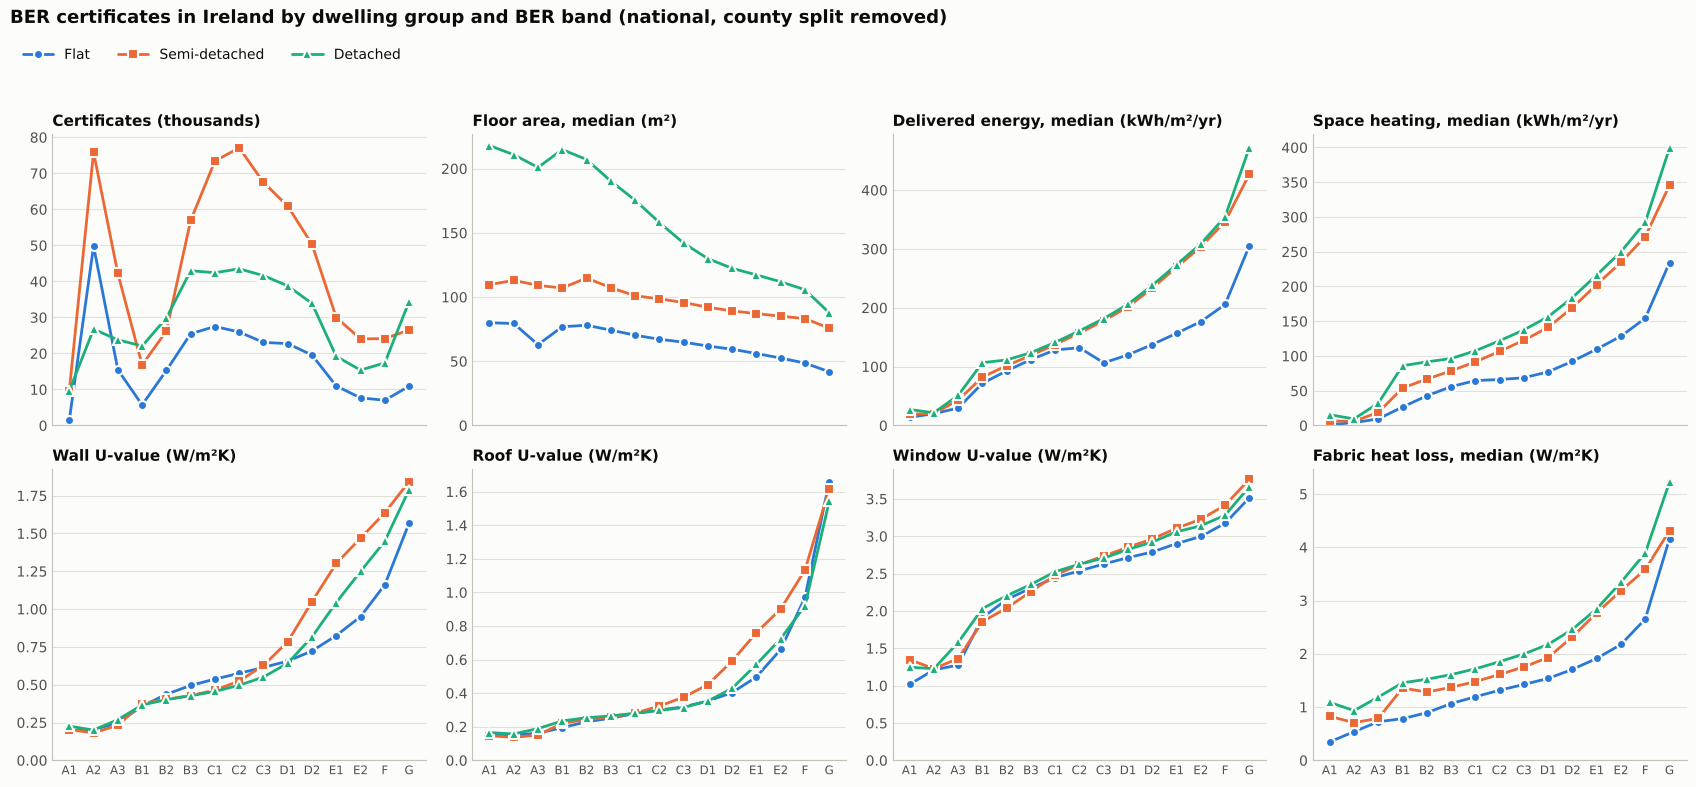

In [27]:
SERIES = {'Flat': ('#2a78d6', 'o'), 'Semi-detached': ('#eb6834', 's'), 'Detached': ('#1baf7a', '^')}
SURFACE, INK, INK_SECONDARY, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
    'axes.labelcolor': INK_SECONDARY, 'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_SECONDARY,
    'ytick.labelcolor': INK_SECONDARY, 'text.color': INK, 'legend.frameon': False,
    'font.family': 'sans-serif', 'font.sans-serif': ['Segoe UI', 'Helvetica Neue', 'Arial', 'DejaVu Sans'],
})

PANELS = [
    ('n_certificates', 'Certificates (thousands)', 1e-3),
    ('total_floor_area_m2_median', 'Floor area, median (m²)', 1),
    ('delivered_total_kwh_m2_median', 'Delivered energy, median (kWh/m²/yr)', 1),
    ('space_heating_kwh_m2_median', 'Space heating, median (kWh/m²/yr)', 1),
    ('u_wall_area_weighted', 'Wall U-value (W/m²K)', 1),
    ('u_roof_area_weighted', 'Roof U-value (W/m²K)', 1),
    ('u_window_area_weighted', 'Window U-value (W/m²K)', 1),
    ('fabric_heat_loss_w_m2k_median', 'Fabric heat loss, median (W/m²K)', 1),
]

fig, axes = plt.subplots(2, 4, figsize=(17, 7.6), sharex=True)
x = np.arange(len(LEGACY_BANDS))
for ax, (col, title, scale) in zip(axes.flat, PANELS):
    for group, (color, marker) in SERIES.items():
        cell = by_band.loc[group].reindex(LEGACY_BANDS)
        y = (cell[col] * scale).where(cell['n_certificates'] >= MIN_CELL_N)
        ax.plot(x, y, color=color, lw=2, marker=marker, ms=6.5, mec=SURFACE, mew=1.5,
                solid_joinstyle='round', solid_capstyle='round', label=group)
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.set_xticks(x, LEGACY_BANDS, fontsize=8.5)
    ax.tick_params(length=0)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='upper left', ncol=3, bbox_to_anchor=(0.005, 0.995),
           fontsize=10, handlelength=2.2)
fig.suptitle('BER certificates in Ireland by dwelling group and BER band (national, county split removed)',
             x=0.005, y=1.03, ha='left', fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.955))
plt.show()

## 8. Export

In [28]:
OUTPUT_DIR.mkdir(exist_ok=True)

def theme_columns(table, theme):
    """Columns of one theme, keeping n_certificates and low_n first."""
    if theme == 'u_values':
        names = [f'u_{e}_{s}' for e in ELEMENTS for s in ('area_weighted', 'median')] + [n for n, _ in SHARES['u_values']]
    else:
        names = [c for name, _, with_n in THEMES[theme]
                 for c in [f'{name}_mean', f'{name}_median'] + ([f'{name}_n'] if with_n else [])]
        names += [n for n, _ in SHARES.get(theme, [])]
    return table[['n_certificates', 'low_n'] + names]

definitions = pd.DataFrame([
    ('n_certificates', 'count', 'Certificates in the cell after cleaning'),
    ('low_n', 'flag', f'True when n_certificates < {MIN_CELL_N}'),
    ('*_mean / *_median', '', 'Mean and median across certificates in the cell'),
    ('*_n', 'count', 'Certificates with a value for that metric (consumption and partially filled indicators)'),
    ('total_floor_area_m2', 'm2', "Total floor area ('GroundFloorArea(sq m)' in the source)"),
    ('wall/roof/floor/window/door_area_m2', 'm2', 'Heat-loss element areas (exposed elements only)'),
    ('glazing_ratio', 'ratio', 'Window area / (wall + window + door area)'),
    ('storeys', 'count', 'Number of storeys'),
    ('delivered_total_kwh(_m2)', 'kWh/yr (kWh/m2/yr)', 'Delivered energy: space + water heating + lighting + pumps and fans'),
    ('space_heating_kwh(_m2)', 'kWh/yr (kWh/m2/yr)', 'Main + secondary space heating, delivered'),
    ('water_heating_kwh(_m2)', 'kWh/yr (kWh/m2/yr)', 'Main + supplementary water heating, delivered'),
    ('lighting_kwh(_m2), pumps_fans_kwh(_m2)', 'kWh/yr (kWh/m2/yr)', 'Delivered'),
    ('u_<element>_area_weighted', 'W/m2K', 'Sum(U x A) / Sum(A) over certificates that have the element'),
    ('u_<element>_median', 'W/m2K', 'Median U over certificates that have the element'),
    ('has_<element>', 'share', 'Share of certificates with that element exposed'),
    ('ber_kwh_m2', 'kWh/m2/yr', 'BerRating: primary energy, net of on-site renewable credits'),
    ('co2_kg_m2', 'kgCO2/m2/yr', 'CO2Rating'),
    ('primary_energy_kwh', 'kWh/yr', 'BerRating x TFA'),
    ('co2_kg', 'kgCO2/yr', 'CO2Rating x TFA'),
    ('fabric_heat_loss_w_m2k', 'W/m2K', '(Sum U x A + thermal bridging factor x Sum A) / TFA; excludes ventilation'),
    ('main_heating_efficiency_pct', '%', 'Main space heating system efficiency (heat pumps above 100%)'),
    ('epc, cpc', 'ratio', 'Energy / Carbon Performance Coefficient (newer DEAP versions only)'),
    ('rer', 'ratio', 'Renewable Energy Ratio (newer DEAP versions only)'),
    ('renewable_elec_kwh', 'kWh/yr', 'Declared on-site renewable electricity (mostly PV)'),
    ('has_pv', 'share', 'Share of certificates with on-site renewable electricity'),
    ('group_heating_share', 'share', 'Share of certificates on group or district heating'),
], columns=['column', 'unit', 'definition'])

settings = pd.DataFrame([
    ('Source file', str(DATA_PATH)), ('Certificates in file', f'{len(raw):,}'), ('Certificates analysed', f'{len(clean):,}'),
    ('Latest assessment date', str(clean['assessment_date'].max().date())),
    ('BER band', 'Re-derived from BerRating on the legacy 15-band scale (A1 to G) for every certificate'),
    ('Geography', 'National: all counties pooled'),
    ('EXCLUDE_PROVISIONAL', EXCLUDE_PROVISIONAL), ('DROP_EXACT_DUPLICATES', DROP_EXACT_DUPLICATES),
    ('INFER_GENERIC_HOUSE', INFER_GENERIC_HOUSE), ('Exposure threshold for legacy House', EXPOSURE_THRESHOLD),
    ('MIN_CELL_N', MIN_CELL_N),
], columns=['setting', 'value'])

workbook = OUTPUT_DIR / 'ber_results_by_type_and_band.xlsx'
with pd.ExcelWriter(workbook) as xl:
    settings.to_excel(xl, sheet_name='settings', index=False)
    definitions.to_excel(xl, sheet_name='definitions', index=False)
    pd.DataFrame(cleaning_log).to_excel(xl, sheet_name='cleaning_log', index=False)
    dwelling_type_map.to_excel(xl, sheet_name='dwelling_type_map', index=False)
    headline.round(3).to_excel(xl, sheet_name='headline_by_letter', merge_cells=False)
    for level, table in [('band', by_band), ('letter', by_letter)]:
        for theme in ['area', 'u_values', 'consumption', 'energy_indicators']:
            theme_columns(table, theme).round(3).to_excel(xl, sheet_name=f'{theme}_by_{level}'[:31], merge_cells=False)
    subtype_counts.to_excel(xl, sheet_name='counts_by_subtype_letter')

by_band.round(3).to_csv(OUTPUT_DIR / 'ber_summary_by_band.csv')
by_letter.round(3).to_csv(OUTPUT_DIR / 'ber_summary_by_letter.csv')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'{path}  ({path.stat().st_size / 1024:,.0f} KB)')

outputs/ber_results_by_type_and_band.xlsx  (73 KB)
outputs/ber_summary_by_band.csv  (35 KB)
outputs/ber_summary_by_letter.csv  (19 KB)
